# CAR REVIEW MODEL ANALYSIS
                        
     THIS MACHINE LEARNING MODEL EVALUATES CAR REVIEWS WHETHER REVIEWS ARE POSTIVE OR NEGATIVE


### SECTION 1 LIBRARY IMPORTS 

In [34]:
import os 
import random
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## this sectionm is for the data splitting and evaluation Metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import(
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# impord-t of the pytorch library, this way we can use the library which contatins the pretrained model(Roberta and the xlnet)
import torch
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    RobertaTokenizer,
    RobertaForSequenceClassification,
    XLNetTokenizer,
    XLNetForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback

)


# SECTION 2 EXPLORATORY DATA ANALYSIS
  THIS SECTION IS FOR CHECKING OF THE DATASET EXPLOARING, CLEANING, AND FILTERING THE NOISE THAT CAN POSSIBLY AFFECT THE LEARNING OF THE MODEL

In [35]:
df = pd.read_csv("car_reviews_.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   review_text                530 non-null    object
 1   car_model                  530 non-null    object
 2   rating                     530 non-null    int64 
 3   year                       530 non-null    int64 
 4   price_range                530 non-null    object
 5   body_type                  530 non-null    object
 6   fuel_type                  530 non-null    object
 7   engine_size                530 non-null    object
 8   transmission               530 non-null    object
 9   ownership_duration_months  530 non-null    int64 
 10  annual_maintenance_cost    530 non-null    int64 
 11  mpg_city                   530 non-null    int64 
 12  mpg_highway                530 non-null    int64 
 13  horsepower                 530 non-null    int64 
 14  reviewer_l

### CHECKING OF NULL VALLUES OR MISSING VALUES

##### CHECKING OF THE NULL VALUES OR MISSNG VALUES FROM EACH COLUMN

In [36]:
print(df.isnull().sum())
print("the total summation of the null values is ",df.isnull().sum().sum())

review_text                  0
car_model                    0
rating                       0
year                         0
price_range                  0
body_type                    0
fuel_type                    0
engine_size                  0
transmission                 0
ownership_duration_months    0
annual_maintenance_cost      0
mpg_city                     0
mpg_highway                  0
horsepower                   0
reviewer_location            0
reviewer_age_group           0
purchase_purpose             0
dtype: int64
the total summation of the null values is  0


##### CHECKNG OF DUPLICATED VALUES

In [37]:
if df.duplicated().any():
    print("duplicates found",df.duplicated.sum().sum())
else:
    print("no duplicates found")

no duplicates found


### CHECKING OF WORD COUNT PER RATE
reason: the roberta model has a 512 token limit so checking the word count per rate could help as make the model training muc faster as we wontbe needing and text truncation and we can set the max length into 128 to make the training much faster

                                         review_text  word_count
0  Terrible experience with this Genesis G90. The...          39
1  The Volkswagen ID.4 is absolutely incredible. ...          35
2  Best Porsche Macan I've ever owned. The Porsch...          39
3  Best Porsche Cayenne I've ever owned. The Pors...          35
4  The Toyota Tacoma is adequate for most needs. ...          26

Word Count Summary:
count    530.000000
mean      35.656604
std        6.034792
min       25.000000
25%       31.000000
50%       35.000000
75%       39.000000
max       57.000000
Name: word_count, dtype: float64


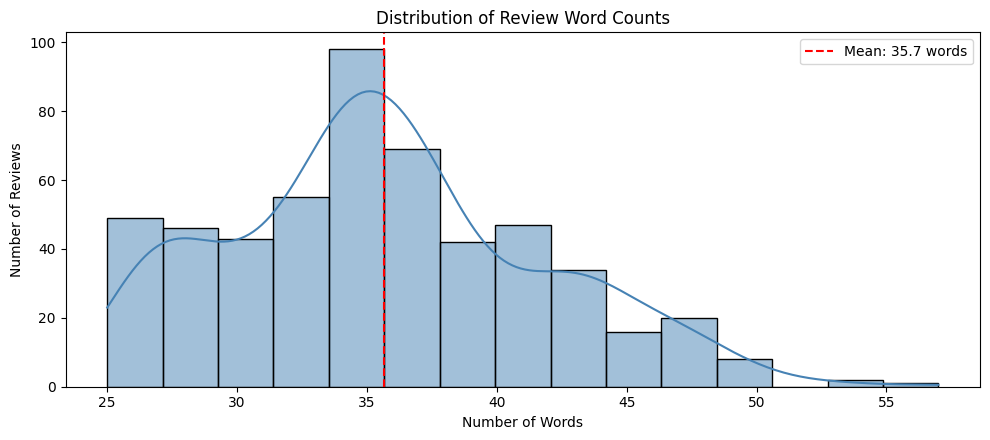

In [43]:
# Remove the accidental column with the stray quote (if it exists)
df = df.drop(columns=["'word_count"], errors='ignore')

# Create the clean 'word_count' column
df['word_count'] = df['review_text'].str.split().str.len()

# Printing of the values per count from the review text field
print(df[['review_text', 'word_count']].head())
print("\nWord Count Summary:")
print(df['word_count'].describe())

# Now in this section we are going to use sns.histplot to plot the distribution and mean of the word counts.
# Since the RoBERTa model has a max limit of 512 tokens per sequence, we want to verify if any reviews
# are too long and need splitting or truncation from the dataset.

# This histplot is for the review word counts
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=df, x='word_count', bins=15, kde=True, color='steelblue', ax=ax)
ax.axvline(df['word_count'].mean(), color='red', linestyle='--', label=f"Mean: {df['word_count'].mean():.1f} words")
ax.set_title('Distribution of Review Word Counts')
ax.set_xlabel('Number of Words')
ax.set_ylabel('Number of Reviews')
ax.legend()

plt.tight_layout()
plt.show()

# EXPLORING THE MOST COMMON WORD FOR EACH RATING
THIS STEP IS NECESSARY FOR MAKING THE MODEL THAT FOCUSES ON THE RULE BASED MODEL


In [ ]:
import pandas as pd                                                                                                                                                      
import matplotlib.pyplot as plt                                                                                                                                                
from wordcloud import WordCloud, STOPWORDS                                                                                                                                     
                                                                                                                                                                                   
    # 1. Load the dataset                                                                                                                                                          
    df = pd.read_csv("car_reviews_.csv")                                                                                                                                           
                                                                                                                                                                                   
    # 2. Add domain-specific stopwords (words you want to ignore so sentiment words stand out)                                                                                     
    custom_stopwords = set(STOPWORDS)                                                                                                                                              
    custom_stopwords.update(["car", "vehicle", "model", "drive", "ownership", "months", "miles"])                                                                                  
                                                                                                                                                                                   
    # 3. Filter reviews into Positive (rating >= 4) and Negative (rating <= 2)                                                                                                     
    pos_text = " ".join(df[df["rating"] >= 4]["review_text"].dropna())                                                                                                             
    neg_text = " ".join(df[df["rating"] <= 2]["review_text"].dropna())                                                                                                             
                                                                                                                                                                                   
    # 4. Generate Word Clouds                                                                                                                                                      
    pos_wc = WordCloud(                                                                                                                                                            
        width=800,                                                                                                                                                                 
        height=400,                                                                                                                                                                
        background_color="white",                                                                                                                                                  
        colormap="Greens",                                                                                                                                                         
        stopwords=custom_stopwords,                                                                                                                                                
        max_words=100                                                                                                                                                              
    ).generate(pos_text)                                                                                                                                                           
                                                                                                                                                                                   
    neg_wc = WordCloud(                                                                                                                                                            
        width=800,                                                                                                                                                                 
        height=400,                                                                                                                                                                
        background_color="white",                                                                                                                                                  
        colormap="Reds",                                                                                                                                                           
        stopwords=custom_stopwords,                                                                                                                                                
        max_words=100
    ).generate(neg_text)
  
    # 5. Display side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
  
    axes[0].imshow(pos_wc, interpolation="bilinear")
    axes[0].set_title("Positive Reviews (Rating 4-5)", fontsize=16, fontweight="bold")
    axes[0].axis("off")
  
    axes[1].imshow(neg_wc, interpolation="bilinear")
    axes[1].set_title("Negative Reviews (Rating 1-2)", fontsize=16, fontweight="bold")
    axes[1].axis("off")
  
    plt.tight_layout()
    plt.show()
  ──────
  3. Extracting Keywords for Your Rule-Based Lexicon
  
  To extract the top words to include in your rule-based dictionary:
  
    # Get top 20 positive and negative words with their frequencies
    top_pos_words = sorted(pos_wc.words_.items(), key=lambda x: x[1], reverse=True)[:20]
    top_neg_words = sorted(neg_wc.words_.items(), key=lambda x: x[1], reverse=True)[:20]
  
    print("Top Positive Keywords for Rules:")
    for word, freq in top_pos_words:
        print(f"  + {word}")
  
    print("\nTop Negative Keywords for Rules:")
    for word, freq in top_neg_words:
        print(f"  - {word}")
  

IndentationError: unexpected indent (3413353252.py, line 48)